# RQ2: Stakeholder Clustering Evaluation
**Research Question 2:** *How effectively does the framework group stakeholders using Shared Nearest Neighbors (SNN)?*

In this phase, we evaluate the clustering quality by iterating through various combinations of fuzzification functions, hesitation degrees, nearest neighbors ($k$), and SNN density quantiles. 

For each configuration, we classify stakeholders into **Core** and **Isolated** groups. We measure the result of the clustering using the **Silhouette Score**, specifically by taking the average silhouette coefficient of the Core stakeholders.

In [1]:
# Import core libraries for data manipulation, clustering evaluation, and performance tracking
import time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import silhouette_samples

# Import custom framework modules for fuzzification, similarity computation, clustering, and consensus feedbackfrom src.data_loader import load_ralic
from src.fuzzification import convert_to_ifv_matrix
from src.similarity import get_similarity_matrices
from src.clustering import get_top_k_neighbors, calculate_snn_matrices, classify_stakeholders
from src.feedback import calculate_group_recommendation, calculate_consensus_degree, calculate_classification
from src.recommender import predict_missing_values
from src.data_loader import load_ralic

# Configure global settings for output clarity and visualization styling
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

### 1. SNN Clustering Grid Search
We load a specified dataset (e.g., Dataset 3: Specific Requirements) and evaluate the SNN density distributions. The algorithm iteratively computes the similarities and clusters the stakeholders based on dynamic density quantiles.

### 1. SNN Clustering Parameter Grid Search
This section systematically evaluates the Shared Nearest Neighbor (SNN) density distributions across the target dataset. The algorithm constructs SNN similarity graphs and adapts to local density variations by classifying stakeholders based on dynamic density quantiles. The goal is to identify the optimal parameter configuration that reliably isolates preference outliers from the core group without relying on predefined cluster centers.

*(Note: The full grid results are computationally intensive. The full calculated results are already saved in the `/results` directory. Adjust the parameters below to test and verify specific configurations.)*

In [2]:
# Define Target Dataset
target_dataset = None

# Full Grid Search Parameters - Uncomment as required to run the full grid search
# fuzzification_methods = ['linear', 'r-trapezoidal', 'sigmoidal']
# hesitancy_degrees = np.arange(0.00, 0.45, 0.05)
# quantiles = np.arange(0.00, 0.55, 0.05)

# Specific Combination Parameters to run specific combinations - Comment as required to run the full grid search
fuzzification_methods = ['r-trapezoidal'] # 'linear', 'r-trapezoidal', 'sigmoidal'
hesitancy_degrees = [0.1] # 0.0 to 0.4 in steps of 0.05
quantiles = [0.15] # 0.0 to 0.5 in steps of 0.05

results = []
total_start_time = time.time()

print(f">>> Loading RALIC Dataset {target_dataset} for Clustering Evaluation...")
df_ralic, _, _, _ = load_ralic(data_id=target_dataset, base_path='../data/')
stakeholders = df_ralic.index.tolist()
n_stakeholders = len(stakeholders)

# Neighbors parameter iterates up to total number of stakeholders - 1
# Uncomment as required to run the full set
# nearest_neighbors = np.arange(1, n_stakeholders)
nearest_neighbors = np.arange(60, 70)

print("Starting Clustering Grid Search...")
print("=" * 85)

# Iterate over fuzzification functions and explicit uncertainty degrees
for method in fuzzification_methods:
    for pi in hesitancy_degrees:
        
        # Transform continuous numeric ratings to Intuitionistic Fuzzy Values (IFVs) and compute H-max similarity
        df_ifv = convert_to_ifv_matrix(
            df_ralic, method=method, pi=pi, 
            scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
        )
        
        dist_matrix, sim_matrix = get_similarity_matrices(df_ifv)

        # Iterate over Number of SNN neighbors (k) to construct SNN graphs
        for k_nn in nearest_neighbors:
            
            # Extract top-k neighbors and construct SNN matrices
            neighbors_map = get_top_k_neighbors(sim_matrix, k=k_nn)
            snn_sim, snn_dist = calculate_snn_matrices(neighbors_map, stakeholders, k=k_nn)
            
            # Iterate over dynamic density quantiles for stakeholder classification
            for q in quantiles:
                
                # Classify into Core and Isolated stakeholders based on quantile threshold
                densities, core, isolated = classify_stakeholders(snn_sim, quantile=q)
                n_noise = len(isolated)
                
                # Silhouette evaluation is only valid if we have both groups (Core and Isolated)
                if len(core) > 0 and len(isolated) > 0:
                    # Map labels exactly as legacy: Core = 0, Isolated/Noise = -1
                    labels = np.array([0 if st in core else -1 for st in stakeholders])
                    
                    # Compute individual silhouette scores using the precomputed H-Max distance matrix
                    sc_samples = silhouette_samples(dist_matrix, labels, metric="precomputed")
                    
                    # Mask to extract average silhouette score strictly for the CORE stakeholders
                    core_mask = (labels == 0)
                    sc_core_avg = np.average(sc_samples[core_mask])
                    
                    # Record evaluation metrics for the current configuration
                    results.append({
                        'fuzzification': method,
                        'uncertainty': round(pi, 2),
                        'quantile': round(q, 2),
                        'nearest_neighbors': k_nn,
                        'silhouette_score': sc_core_avg,
                        'n_noise': n_noise
                    })
                    print(f"{method:<4} | uncertainty: {round(pi, 2):<4} | quantile: {round(q, 2):.2f} | k_nn: {k_nn:<2} --> sc: {sc_core_avg:.3f} | n_noise: {n_noise}")
        
        # Output progress per fuzzification and uncertainty configuration
        print(f"Completed processing: {method} | pi: {pi:.2f}")

print("=" * 85)
print(f"Clustering Grid Search Complete in {time.time() - total_start_time:.2f} seconds.")

# Create the final results DataFrame
df_results = pd.DataFrame(results)
display(df_results)

>>> Loading RALIC Dataset None for Clustering Evaluation...
Starting Clustering Grid Search...
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 60 --> sc: 0.734 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 61 --> sc: 0.734 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 62 --> sc: 0.734 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 63 --> sc: 0.734 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 64 --> sc: 0.735 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 65 --> sc: 0.735 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 66 --> sc: 0.735 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 67 --> sc: 0.712 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 68 --> sc: 0.729 | n_noise: 12
r-trapezoidal | uncertainty: 0.1  | quantile: 0.15 | k_nn: 69 --> sc: 0.720 | n_noise: 12
Compl

,fuzzification,uncertainty,quantile,nearest_neighbors,silhouette_score,n_noise
0,r-trapezoidal,0.1,0.15,60,0.734136,12
1,r-trapezoidal,0.1,0.15,61,0.734136,12
2,r-trapezoidal,0.1,0.15,62,0.734136,12
3,r-trapezoidal,0.1,0.15,63,0.734136,12
4,r-trapezoidal,0.1,0.15,64,0.734763,12
5,r-trapezoidal,0.1,0.15,65,0.734763,12
6,r-trapezoidal,0.1,0.15,66,0.734763,12
7,r-trapezoidal,0.1,0.15,67,0.712389,12
8,r-trapezoidal,0.1,0.15,68,0.728773,12
9,r-trapezoidal,0.1,0.15,69,0.719875,12


### 2. Exporting Results
Display the generated results

### 2. Exporting and Analyzing Clustering Results
The resulting configurations are ranked by their Silhouette Coefficient to identify the optimal parameters for separating core and isolated stakeholders across different intuitionistic fuzzification functions.

*(Note: The full grid results are already saved as csv files in the /results folder and loaded for further analysis.)*

In [3]:
# Export the Full Grid Search Results
# results_path = f'../results/rq2_results_clustering.csv'
# df_results.to_csv(results_path, index=False)
# print(f"Clustering results successfully saved to '{results_path}'.")

import pandas as pd

results_path = '../results/rq2_results_clustering.csv'
df_clustering = pd.read_csv(results_path)

# Rank configurations by Silhouette Coefficient (Descending: highest first)
df_sorted = df_clustering.sort_values(by='silhouette_score', ascending=False)

# Extract top-performing configurations per fuzzification method and explicit hesitation degree
top_per_combination = df_sorted.groupby(['fuzzification', 'uncertainty']).head(1)

# Organize the final output by function and uncertainty
top_per_combination = top_per_combination.sort_values(
    by=['fuzzification', 'uncertainty', 'silhouette_score'],
    ascending=[True, True, False]
).reset_index(drop=True)

print("--- Top Clustering Configurations per Fuzzification & Uncertainty ---")

# Display metrics
display(top_per_combination.style.format({
    'uncertainty': '{:.2f}',
    'quantile': '{:.2f}',
    'silhouette_score': '{:.3f}',
    'n_noise': '{:.0f}'
}).hide(axis="index"))

--- Top Clustering Configurations per Fuzzification & Uncertainty ---


fuzzification,uncertainty,quantile,nearest_neighbors,silhouette_score,n_noise
linear,0.00,0.15,63,0.636,12
linear,0.05,0.10,69,0.614,8
linear,0.10,0.10,69,0.591,8
linear,0.15,0.10,63,0.567,8
linear,0.20,0.10,68,0.543,8
linear,0.25,0.50,42,0.529,38
linear,0.30,0.50,42,0.526,39
linear,0.35,0.50,43,0.513,38
linear,0.40,0.50,42,0.505,38
r-trapezoidal,0.00,0.50,28,0.817,38


### 3. Feedback and Consensus Evaluation
In this phase, we evaluate the system's ability to improve the overall Consensus Degree (CD). We simulate an ideal scenario where the stakeholders classified as **Isolated** agree to modify their preferences and adopt the **Group Recommendation (GR)**.

The GR is generated by averaging the *predicted* complete profiles of the **Core** stakeholders. We then apply this GR to the isolated stakeholders in the *initial* matrix and recalculate the global similarity to measure the Consensus Degree Improvement ($\\Delta CD$).

*(Note: The full grid results are computationally intensive. The full calculated results are already saved in the `/results` directory. Adjust the parameters below to test and verify specific configurations.)*

In [4]:
# Define Target Dataset
target_dataset = None
df_ralic, _, _, _ = load_ralic(data_id=target_dataset, base_path='../data/')
stakeholders = df_ralic.index.tolist()

# Full Grid Search Parameters - Uncomment as required to run the full grid search
# fuzzification_methods = ['linear', 'r-trapezoidal', 'sigmoidal']
# hesitancy_degrees = np.arange(0.10, 0.40, 0.10)
# top_recommenders = np.arange(10, 51)
# clustering_nearest_neighbors = np.arange(50, 66)
# quantiles = np.arange(0.10, 0.35, 0.05)
# prediction_strategy = 'global'

# Specific Combination Parameters to run specific combinations - Comment as required to run the full grid search
fuzzification_methods = ['linear']
hesitancy_degrees = [0.1]
top_recommenders = [15]
clustering_nearest_neighbors = [54]
quantiles = [0.2]
prediction_strategy = 'global'

results_feedback = []
total_feedback_start = time.time()

print("Starting Feedback & Consensus Grid Search...")
print("=" * 85)

for method in fuzzification_methods:
    for pi in hesitancy_degrees:
        loop_timer = time.time()

        # Establish the baseline Intuitionistic Fuzzy Value (IFV) matrix
        df_ifv = convert_to_ifv_matrix(
            df_ralic, method=method, pi=pi,
            scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
        )
        dist_matrix, sim_matrix = get_similarity_matrices(df_ifv)

        # Calculate Initial Consensus Degree (CD) prior to preference modification
        base_cd = calculate_consensus_degree(sim_matrix)

        # Predict missing evaluations using collaborative filtering to mitigate data sparsity
        for pred_k in top_recommenders:
            df_predicted = predict_missing_values(df_ifv, sim_matrix, k=pred_k, strategy=prediction_strategy)

            # Construct SNN matrices to evaluate local neighborhood densities
            for clus_k in clustering_nearest_neighbors:
                neighbors_map = get_top_k_neighbors(sim_matrix, k=clus_k)
                snn_sim, snn_dist = calculate_snn_matrices(neighbors_map, stakeholders, k=clus_k)

                # Classify stakeholders into core and isolated groups
                for q in quantiles:
                    densities, core, isolated = classify_stakeholders(snn_sim, quantile=q)

                    updated_cd = base_cd  # Fallback if no valid split

                    if len(core) > 0 and len(isolated) > 0:
                        # Synthesize the Group Recommendation (GR) by aggregating the predicted profiles of core stakeholders
                        gr_series = calculate_group_recommendation(df_predicted, core)

                        # Simulate preference modification by aligning isolated stakeholders with the consensus focal point (GR)
                        df_final_ifv = df_ifv.copy()
                        for st in isolated:
                            df_final_ifv.loc[st] = gr_series

                        # Recalculate CD
                        _, updated_sim_matrix = get_similarity_matrices(df_final_ifv)
                        updated_cd = calculate_consensus_degree(updated_sim_matrix)

                    # Record consensus metrics for the current configuration
                    results_feedback.append({
                        'fuzzification': method,
                        'uncertainty': round(pi, 2),
                        'top_n_recommenders': pred_k,
                        'clustering_k_nearest_neighbors': clus_k,
                        'quantile': round(q, 2),
                        'consensus_degree': base_cd,
                        'consensus_degree_updated': updated_cd
                    })
                    print(f"{method:<4} | pi: {round(pi, 2):<4} | top_n: {pred_k} | clust_k_nn: {clus_k:<2} "
                          f"| quantile: {q:.2f} | cd: {base_cd:.3f} | ucd: {updated_cd:.3f} | Δcd: {updated_cd-base_cd:.3f}")

        print(f"Processed {method:<18} | pi: {pi:.2f} | Time: {time.time() - loop_timer:.2f}s")

print("=" * 85)
print(f"Feedback Grid Search Complete in {time.time() - total_feedback_start:.2f} seconds.")
df_feedback_results = pd.DataFrame(results_feedback)
display(df_feedback_results)

Starting Feedback & Consensus Grid Search...
linear | pi: 0.1  | top_n: 15 | clust_k_nn: 54 | quantile: 0.20 | cd: 0.758 | ucd: 0.852 | Δcd: 0.094
Processed linear             | pi: 0.10 | Time: 3.41s
Feedback Grid Search Complete in 3.41 seconds.


,fuzzification,uncertainty,top_n_recommenders,clustering_k_nearest_neighbors,quantile,consensus_degree,consensus_degree_updated
0,linear,0.1,15,54,0.2,0.7582,0.8521


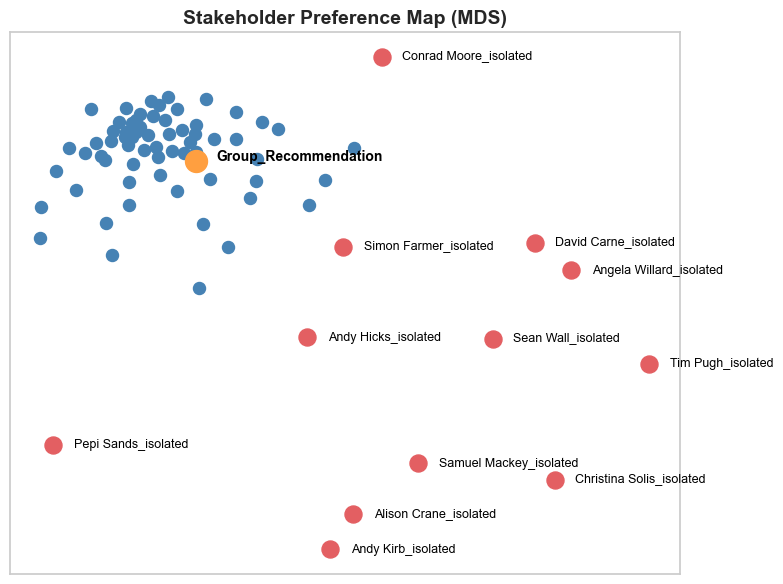

In [5]:
from src.visualization import plot_stakeholder_map

method='r-trapezoidal'
pi=0.1
quantile=0.15
k=65

df_ifv = convert_to_ifv_matrix(df_ralic, method=method, pi=pi, scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0)
dist_matrix, sim_matrix = get_similarity_matrices(df_ifv)

neighbors_map = get_top_k_neighbors(sim_matrix, k=k)
snn_sim, snn_dist = calculate_snn_matrices(neighbors_map, stakeholders, k=k)

densities, core, isolated = classify_stakeholders(snn_sim, quantile=quantile)
gr_series = calculate_group_recommendation(df_ifv, core)

plot_stakeholder_map(dist_matrix, core, isolated, gr_series, df_ifv, '../results/rq2_clustering_visualization.png')

### 4. Export Feedback Results and Analyze Top Improvements
We save the generated matrix to CSV and extract the configurations that yielded the highest absolute improvement in Consensus Degree.

*(Note: The full grid results are already saved as csv files in the /results folder and loaded for further analysis.)*

In [6]:
# Export the Full Grid Search Results
# df_feedback_results = pd.DataFrame(results_feedback)
# feedback_results_path = '../results/rq2_results_feedback.csv'
# df_feedback_results.to_csv(feedback_results_path, index=False)
# print(f"Feedback results successfully saved to '{feedback_results_path}'.\n")

import pandas as pd

results_path = '../results/rq2_results_feedback.csv'
df_feedback_results = pd.read_csv(results_path)

# Compute the absolute improvement in Consensus Degree (ΔCD) resulting from the feedback mechanism
df_analysis = df_feedback_results.copy()
df_analysis['cd_improvement'] = df_analysis['consensus_degree_updated'] - df_analysis['consensus_degree']

# Sort by Highest Improvement
df_sorted = df_analysis.sort_values(by='cd_improvement', ascending=False)

# Extract top performing configurations per fuzzification method and explicit hesitation degree
top_5_feedback = df_sorted.groupby(['fuzzification', 'uncertainty']).head(1)

# Organize the analytical output for reporting
top_5_feedback = top_5_feedback.sort_values(
    by=['fuzzification', 'uncertainty', 'cd_improvement'],
    ascending=[True, True, False]
).reset_index(drop=True)

print("--- Top 5 Feedback Configurations per Fuzzification & Uncertainty ---")
display(top_5_feedback.style.format({
    'uncertainty': '{:.2f}',
    'quantile': '{:.2f}',
    'consensus_degree': '{:.3f}',
    'consensus_degree_updated': '{:.3f}',
    'cd_improvement': '{:+.3f}'
}))

--- Top 5 Feedback Configurations per Fuzzification & Uncertainty ---


,fuzzification,uncertainty,top_n_recommenders,clustering_k_nearest_neighbors,quantile,consensus_degree,consensus_degree_updated,cd_improvement
0,linear,0.10,49,56,0.30,0.758,0.874,+0.116
1,linear,0.20,46,51,0.30,0.748,0.857,+0.110
2,linear,0.30,48,56,0.30,0.738,0.842,+0.104
3,linear,0.40,47,52,0.30,0.727,0.829,+0.101
4,r-trapezoidal,0.10,48,53,0.30,0.768,0.917,+0.149
5,r-trapezoidal,0.20,48,55,0.30,0.757,0.896,+0.139
6,r-trapezoidal,0.30,50,53,0.30,0.745,0.874,+0.129
7,r-trapezoidal,0.40,48,53,0.30,0.734,0.852,+0.118
8,sigmoidal,0.10,44,52,0.30,0.804,0.950,+0.145
9,sigmoidal,0.20,48,53,0.30,0.826,0.955,+0.129
